In [ ]:
import torch
print("CUDA available:", torch.cuda.is_available())
print("Device name:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

CUDA available: True
Device name: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
print(os.listdir('/content/drive/MyDrive/labelled_export'))  # adjust path to find your folder

['README.roboflow.txt', 'README.dataset.txt', 'test', 'valid', 'train']


In [ ]:
import shutil

shutil.copytree('/content/drive/MyDrive/labelled_export', '/content/dataset')
print(os.listdir('/content/dataset'))

['valid', 'README.roboflow.txt', 'train', 'README.dataset.txt', 'test']


In [ ]:
!pip install pycocotools albumentations --quiet

In [ ]:
#verifying the COCO annotations load correctly

import json

with open('/content/dataset/train/_annotations.coco.json') as f:
    train_data = json.load(f)

print(f"Images: {len(train_data['images'])}")
print(f"Annotations: {len(train_data['annotations'])}")
print(f"Categories: {train_data['categories']}")

# Look at one annotation's structure
print("\nSample annotation:")
print(train_data['annotations'][0])

Images: 62
Annotations: 62
Categories: [{'id': 0, 'name': 'object', 'supercategory': 'none'}, {'id': 1, 'name': 'phone_box', 'supercategory': 'object'}]

Sample annotation:
{'id': 1, 'image_id': 0, 'category_id': 1, 'bbox': [780, 522, 1377, 2781], 'iscrowd': 0, 'area': 3829437, 'segmentation': {'counts': '_RYb2i5SU3o4kKn0XO>mUMWDVc2e>PXM`AiNQ3_g2Qb0mNd2RZMPXOcb2Xj0_Nk0TO]1dN_1aNP1XcMQQO^Z2QQ1XOb2^Mi0VO8I;Ef0ZOl0TOg0YOT1lNP1\\oMmhN[j1m]1TSN[`N[j1ab1TN8H^1mWNU[NUf1Wf1d[Nn[NR_1cd1k^NgYNb0Y2[`1ci1bN`1TaNiRNo[1[o1YOk0UO_1aN]1cNf0ZO\\2RiNQjMRS1jW2E=Ca0fnNPhMbm0S^2TM\\2dM\\1dNP1PO;E:F:F9G4L4L3M3M2N1O2N1O1O1O1O001O00001O001O00001O00001O0000001O00001O00000000000000001O000000000000000000001O00000O10000001O0000000000000000000000000000000000000000000000O100000O100000000000000000000000000000000O100000000000000000000000000000000000000000000000000000000000000000000O100000000000000000000000000000000000000000001O0O100000000000000000000000000O10000000000000000O100000000000000O10000000O10000000O100000000

In [ ]:
#Data loader

from pycocotools import mask as coco_mask
from pycocotools.coco import COCO
import numpy as np
import cv2
import os

def load_mask_from_annotation(ann, height, width):
    """Decode a COCO RLE or polygon annotation into a binary mask."""
    seg = ann['segmentation']
    if isinstance(seg, dict):  # RLE format
        rle = seg
        mask = coco_mask.decode(rle)
    else:  # polygon format (list of lists)
        rles = coco_mask.frPyObjects(seg, height, width)
        rle = coco_mask.merge(rles)
        mask = coco_mask.decode(rle)
    return mask  # 2D numpy array, values 0 or 1

# --- Quick test on your sample annotation ---
coco = COCO('/content/dataset/train/_annotations.coco.json')
img_info = coco.loadImgs(train_data['annotations'][0]['image_id'])[0]
print(img_info)

mask = load_mask_from_annotation(train_data['annotations'][0], img_info['height'], img_info['width'])
print("Mask shape:", mask.shape)
print("Unique values:", np.unique(mask))
print("Foreground pixel count:", mask.sum())

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
{'id': 0, 'license': 1, 'file_name': 'Box_17_jpg.rf.PII4hYoDOZrzFAHrje4k.jpg', 'height': 3456, 'width': 3456, 'date_captured': '2026-07-18T19:32:22+00:00', 'extra': {'name': 'Box_17.jpg'}}
Mask shape: (3456, 3456)
Unique values: [0 1]
Foreground pixel count: 3643485


In [ ]:
#Building the model
!pip install segmentation-models-pytorch --quiet

import segmentation_models_pytorch as smp
import torch

model = smp.Unet(
    encoder_name="resnet34",        # pretrained encoder backbone
    encoder_weights="imagenet",     # use ImageNet-pretrained weights
    in_channels=3,                  # RGB input
    classes=1,                      # single class: phone_box (binary mask)
    activation=None                 # we'll apply sigmoid ourselves during loss/inference
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)
print(f"Model loaded on {device}")
print(f"Total parameters: {sum(p.numel() for p in model.parameters()):,}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 5.5 MB/s eta 0:00:00


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Model loaded on cuda
Total parameters: 24,436,369


In [ ]:
import torch
from torch.utils.data import Dataset
from pycocotools.coco import COCO
from pycocotools import mask as coco_mask
import cv2
import numpy as np
import os

class PhoneBoxDataset(Dataset):
    def __init__(self, images_dir, annotation_file, img_size=512, augment=False):
        self.images_dir = images_dir
        self.coco = COCO(annotation_file)
        self.image_ids = list(self.coco.imgs.keys())
        self.img_size = img_size
        self.augment = augment

    def __len__(self):
        return len(self.image_ids)

    def _decode_mask(self, ann, height, width):
        seg = ann['segmentation']
        if isinstance(seg, dict):  # RLE
            mask = coco_mask.decode(seg)
        else:  # polygon
            rles = coco_mask.frPyObjects(seg, height, width)
            rle = coco_mask.merge(rles)
            mask = coco_mask.decode(rle)
        return mask

    def __getitem__(self, idx):
        img_id = self.image_ids[idx]
        img_info = self.coco.loadImgs(img_id)[0]
        img_path = os.path.join(self.images_dir, img_info['file_name'])

        # Load image
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        h, w = img_info['height'], img_info['width']

        # Load and merge all annotations for this image (should be just 1 - phone_box)
        ann_ids = self.coco.getAnnIds(imgIds=img_id)
        anns = self.coco.loadAnns(ann_ids)

        mask = np.zeros((h, w), dtype=np.uint8)
        for ann in anns:
            if ann['category_id'] == 1:  # phone_box class only, skip the 'object' placeholder
                m = self._decode_mask(ann, h, w)
                mask = np.maximum(mask, m)

        # Resize both image and mask to the same target size
        image = cv2.resize(image, (self.img_size, self.img_size), interpolation=cv2.INTER_LINEAR)
        mask = cv2.resize(mask, (self.img_size, self.img_size), interpolation=cv2.INTER_NEAREST)
        # INTER_NEAREST for mask is important — avoids introducing fractional/blurry values at edges

        # Normalize image to [0,1], convert to tensor, channels-first
        image = image.astype(np.float32) / 255.0
        image = torch.from_numpy(image).permute(2, 0, 1)  # HWC -> CHW

        mask = torch.from_numpy(mask).float().unsqueeze(0)  # add channel dim -> (1, H, W)

        return image, mask

In [ ]:
train_dataset = PhoneBoxDataset(
    images_dir='/content/dataset/train',
    annotation_file='/content/dataset/train/_annotations.coco.json',
    img_size=512
)

img, mask = train_dataset[0]
print("Image shape:", img.shape, img.dtype)
print("Mask shape:", mask.shape, mask.dtype)
print("Mask unique values:", torch.unique(mask))
print("Dataset length:", len(train_dataset))

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Image shape: torch.Size([3, 512, 512]) torch.float32
Mask shape: torch.Size([1, 512, 512]) torch.float32
Mask unique values: tensor([0., 1.])
Dataset length: 62


In [ ]:
from torch.utils.data import DataLoader

train_dataset = PhoneBoxDataset(
    images_dir='/content/dataset/train',
    annotation_file='/content/dataset/train/_annotations.coco.json',
    img_size=512
)

val_dataset = PhoneBoxDataset(
    images_dir='/content/dataset/valid',
    annotation_file='/content/dataset/valid/_annotations.coco.json',
    img_size=512
)

test_dataset = PhoneBoxDataset(
    images_dir='/content/dataset/test',
    annotation_file='/content/dataset/test/_annotations.coco.json',
    img_size=512
)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2)

print(f"Train batches: {len(train_loader)}, Val batches: {len(val_loader)}, Test batches: {len(test_loader)}")

loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
loading annotations into memory...
Done (t=0.00s)
creating index...
index created!
Train batches: 16, Val batches: 3, Test batches: 5


In [ ]:
import torch
import torch.nn as nn

class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.bce_weight = bce_weight

    def dice_loss(self, logits, targets, smooth=1e-6):
        probs = torch.sigmoid(logits)
        probs = probs.view(-1)
        targets = targets.view(-1)
        intersection = (probs * targets).sum()
        dice = (2. * intersection + smooth) / (probs.sum() + targets.sum() + smooth)
        return 1 - dice

    def forward(self, logits, targets):
        bce_loss = self.bce(logits, targets)
        dice_loss = self.dice_loss(logits, targets)
        return self.bce_weight * bce_loss + (1 - self.bce_weight) * dice_loss

criterion = BCEDiceLoss(bce_weight=0.5)

In [ ]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

In [ ]:
def compute_iou(logits, targets, threshold=0.5, smooth=1e-6):
    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()
    intersection = (preds * targets).sum()
    union = preds.sum() + targets.sum() - intersection
    return ((intersection + smooth) / (union + smooth)).item()

In [ ]:
import time
import json
import os
from google.colab import drive

# --- Ensure Drive is mounted ---
drive.mount('/content/drive', force_remount=False)

DRIVE_DIR = "/content/drive/MyDrive/phone_box_training"
os.makedirs(DRIVE_DIR, exist_ok=True)
WEIGHTS_PATH = os.path.join(DRIVE_DIR, "best_unet_resnet34.pth")
HISTORY_PATH = os.path.join(DRIVE_DIR, "training_history.json")

num_epochs = 30
train_losses, val_losses, val_ious = [], [], []
best_iou = 0

for epoch in range(num_epochs):
    start = time.time()

    # --- Training ---
    model.train()
    running_loss = 0.0
    for images, masks in train_loader:
        images, masks = images.to(device), masks.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_train_loss = running_loss / len(train_dataset)
    train_losses.append(epoch_train_loss)

    # --- Validation ---
    model.eval()
    running_val_loss = 0.0
    running_iou = 0.0
    with torch.no_grad():
        for images, masks in val_loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            loss = criterion(outputs, masks)
            running_val_loss += loss.item() * images.size(0)
            running_iou += compute_iou(outputs, masks) * images.size(0)

    epoch_val_loss = running_val_loss / len(val_dataset)
    epoch_val_iou = running_iou / len(val_dataset)
    val_losses.append(epoch_val_loss)
    val_ious.append(epoch_val_iou)

    # --- Save best weights directly to Drive ---
    if epoch_val_iou > best_iou:
        best_iou = epoch_val_iou
        torch.save(model.state_dict(), WEIGHTS_PATH)

    # --- Save history to Drive every epoch (survives disconnects) ---
    with open(HISTORY_PATH, "w") as f:
        json.dump({
            "train_losses": train_losses,
            "val_losses": val_losses,
            "val_ious": val_ious,
            "completed_epochs": epoch + 1
        }, f)

    elapsed = time.time() - start
    print(f"Epoch {epoch+1}/{num_epochs} | Train Loss: {epoch_train_loss:.4f} | "
          f"Val Loss: {epoch_val_loss:.4f} | Val IoU: {epoch_val_iou:.4f} | Time: {elapsed:.1f}s")

print(f"\nTraining complete. Best IoU: {best_iou:.4f}")
print(f"Weights: {WEIGHTS_PATH}")
print(f"History: {HISTORY_PATH}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1/30 | Train Loss: 0.4585 | Val Loss: 0.5044 | Val IoU: 0.5874 | Time: 18.6s
Epoch 2/30 | Train Loss: 0.3249 | Val Loss: 0.3140 | Val IoU: 0.8252 | Time: 12.0s
Epoch 3/30 | Train Loss: 0.2745 | Val Loss: 0.2626 | Val IoU: 0.9007 | Time: 13.0s
Epoch 4/30 | Train Loss: 0.2426 | Val Loss: 0.2361 | Val IoU: 0.9352 | Time: 13.3s
Epoch 5/30 | Train Loss: 0.2196 | Val Loss: 0.2196 | Val IoU: 0.9516 | Time: 13.3s
Epoch 6/30 | Train Loss: 0.2033 | Val Loss: 0.1987 | Val IoU: 0.9537 | Time: 10.1s
Epoch 7/30 | Train Loss: 0.1930 | Val Loss: 0.1886 | Val IoU: 0.9522 | Time: 13.7s
Epoch 8/30 | Train Loss: 0.1714 | Val Loss: 0.1686 | Val IoU: 0.9608 | Time: 12.3s
Epoch 9/30 | Train Loss: 0.1544 | Val Loss: 0.1564 | Val IoU: 0.9626 | Time: 13.3s
Epoch 10/30 | Train Loss: 0.1434 | Val Loss: 0.1397 | Val IoU: 0.9711 | Time: 13.5s
Epoch 11/30 | Train Loss: 0.1349 | Val L

In [ ]:
torch.save(model.state_dict(), "best_unet_resnet34.pth")

In [ ]:
best_iou = 0

...

if epoch_val_iou > best_iou:
    best_iou = epoch_val_iou
    torch.save(model.state_dict(), "best_unet_resnet34.pth")

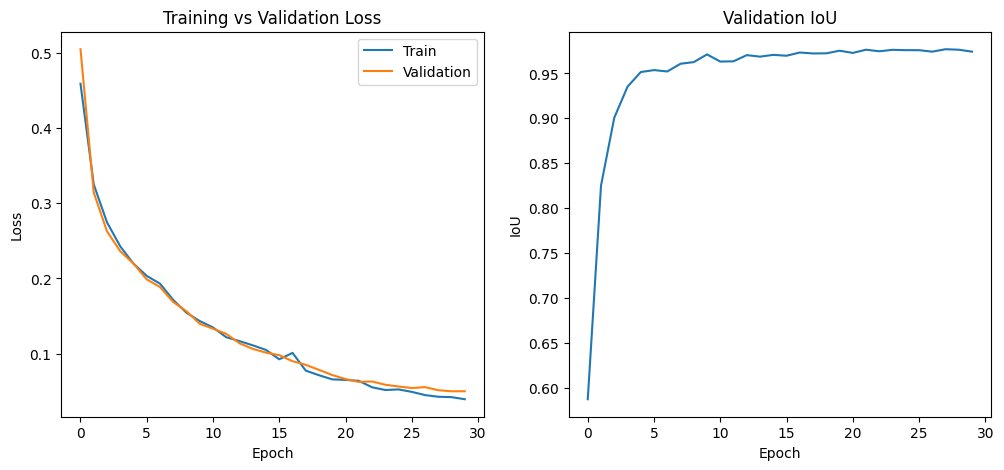

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)
plt.plot(train_losses,label="Train")
plt.plot(val_losses,label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Training vs Validation Loss")

plt.subplot(1,2,2)
plt.plot(val_ious)
plt.xlabel("Epoch")
plt.ylabel("IoU")
plt.title("Validation IoU")

plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

model.load_state_dict(torch.load("best_unet_resnet34.pth"))
model.eval()

Mounted at /content/drive


NameError: name 'model' is not defined

In [ ]:
image, mask = val_dataset[5]

In [ ]:
with torch.no_grad():
    pred = model(image.unsqueeze(0).to(device))
    pred = torch.sigmoid(pred)
    pred = (pred > 0.5).float()


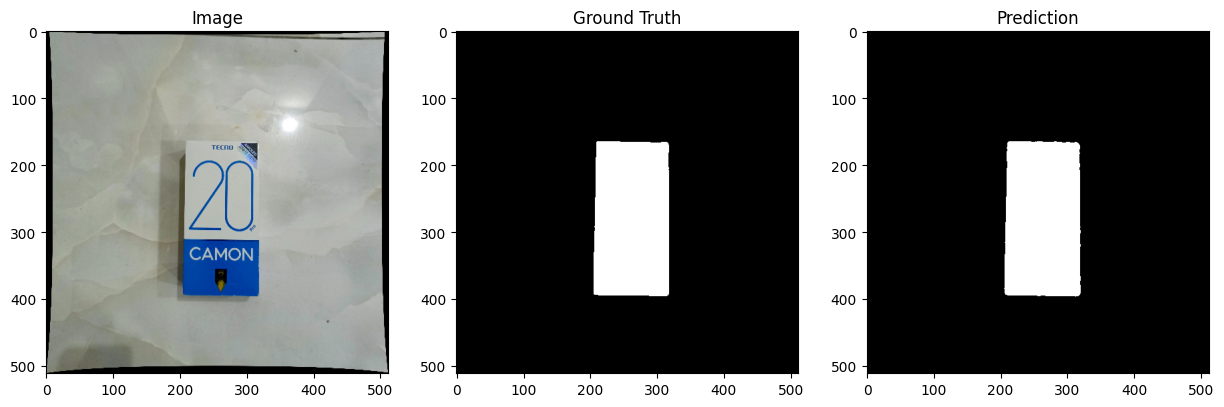

In [ ]:
fig, ax = plt.subplots(1,3,figsize=(15,5))

ax[0].imshow(image.permute(1,2,0))
ax[0].set_title("Image")

ax[1].imshow(mask.squeeze(), cmap="gray")
ax[1].set_title("Ground Truth")

ax[2].imshow(pred.cpu().squeeze(), cmap="gray")
ax[2].set_title("Prediction")

plt.show()

In [ ]:
import torch

def segmentation_metrics(logits, targets, threshold=0.5, smooth=1e-6):
    """
    Returns:
        IoU
        Dice
        Precision
        Recall
        F1
        Pixel Accuracy
    """

    probs = torch.sigmoid(logits)
    preds = (probs > threshold).float()

    preds = preds.view(-1)
    targets = targets.view(-1)

    TP = (preds * targets).sum()
    FP = (preds * (1 - targets)).sum()
    FN = ((1 - preds) * targets).sum()
    TN = ((1 - preds) * (1 - targets)).sum()

    iou = (TP + smooth) / (TP + FP + FN + smooth)

    dice = (2 * TP + smooth) / (2 * TP + FP + FN + smooth)

    precision = (TP + smooth) / (TP + FP + smooth)

    recall = (TP + smooth) / (TP + FN + smooth)

    f1 = (2 * precision * recall + smooth) / (precision + recall + smooth)

    pixel_acc = (TP + TN + smooth) / (TP + TN + FP + FN + smooth)

    return (
        iou.item(),
        dice.item(),
        precision.item(),
        recall.item(),
        f1.item(),
        pixel_acc.item(),
    )

In [ ]:
model.eval()

iou_scores = []
dice_scores = []
precision_scores = []
recall_scores = []
f1_scores = []
pixel_acc_scores = []

with torch.no_grad():

    for images, masks in val_loader:

        images = images.to(device)
        masks = masks.to(device)

        outputs = model(images)

        for i in range(images.size(0)):

            iou, dice, precision, recall, f1, pixel_acc = segmentation_metrics(
                outputs[i],
                masks[i]
            )

            iou_scores.append(iou)
            dice_scores.append(dice)
            precision_scores.append(precision)
            recall_scores.append(recall)
            f1_scores.append(f1)
            pixel_acc_scores.append(pixel_acc)

In [ ]:
print("=" * 40)
print("Validation Metrics")
print("=" * 40)

print(f"Mean IoU          : {sum(iou_scores)/len(iou_scores):.4f}")
print(f"Mean Dice Score   : {sum(dice_scores)/len(dice_scores):.4f}")
print(f"Mean Precision    : {sum(precision_scores)/len(precision_scores):.4f}")
print(f"Mean Recall       : {sum(recall_scores)/len(recall_scores):.4f}")
print(f"Mean F1-score     : {sum(f1_scores)/len(f1_scores):.4f}")
print(f"Pixel Accuracy    : {sum(pixel_acc_scores)/len(pixel_acc_scores):.4f}")

Validation Metrics
Mean IoU          : 0.9679
Mean Dice Score   : 0.9835
Mean Precision    : 0.9818
Mean Recall       : 0.9854
Mean F1-score     : 0.9835
Pixel Accuracy    : 0.9941


In [ ]:
def evaluate_dataset(model, loader, device, threshold=0.5, smooth=1e-6):
    model.eval()
    ious, dices, precisions, recalls, f1s, pixel_accs = [], [], [], [], [], []

    with torch.no_grad():
        for images, masks in loader:
            images, masks = images.to(device), masks.to(device)
            outputs = model(images)
            probs = torch.sigmoid(outputs)
            preds = (probs > threshold).float()

            for i in range(images.size(0)):
                pred = preds[i].view(-1)
                target = masks[i].view(-1)

                intersection = (pred * target).sum()
                union = pred.sum() + target.sum() - intersection
                iou = ((intersection + smooth) / (union + smooth)).item()

                dice = ((2 * intersection + smooth) / (pred.sum() + target.sum() + smooth)).item()

                tp = intersection
                fp = (pred * (1 - target)).sum()
                fn = ((1 - pred) * target).sum()
                precision = ((tp + smooth) / (tp + fp + smooth)).item()
                recall = ((tp + smooth) / (tp + fn + smooth)).item()
                f1 = (2 * precision * recall) / (precision + recall + smooth)

                pixel_acc = (pred == target).float().mean().item()

                ious.append(iou)
                dices.append(dice)
                precisions.append(precision)
                recalls.append(recall)
                f1s.append(f1)
                pixel_accs.append(pixel_acc)

    print("=" * 60)
    print("TEST SET Metrics")
    print("=" * 60)
    print(f"Mean IoU          : {np.mean(ious):.4f}")
    print(f"Mean Dice Score   : {np.mean(dices):.4f}")
    print(f"Mean Precision    : {np.mean(precisions):.4f}")
    print(f"Mean Recall       : {np.mean(recalls):.4f}")
    print(f"Mean F1-score     : {np.mean(f1s):.4f}")
    print(f"Pixel Accuracy    : {np.mean(pixel_accs):.4f}")

    return ious, dices, precisions, recalls, f1s, pixel_accs

import numpy as np
test_metrics = evaluate_dataset(model, test_loader, device)

TEST SET Metrics
Mean IoU          : 0.9867
Mean Dice Score   : 0.9933
Mean Precision    : 0.9901
Mean Recall       : 0.9965
Mean F1-score     : 0.9933
Pixel Accuracy    : 0.9962


In [ ]:
model.load_state_dict(torch.load("/content/drive/MyDrive/best_unet_resnet34.pth"))
model.eval()

Unet(
  (encoder): ResNetEncoder(
    (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu): ReLU(inplace=True)
    (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (layer1): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track

Loaded 30 epochs of history


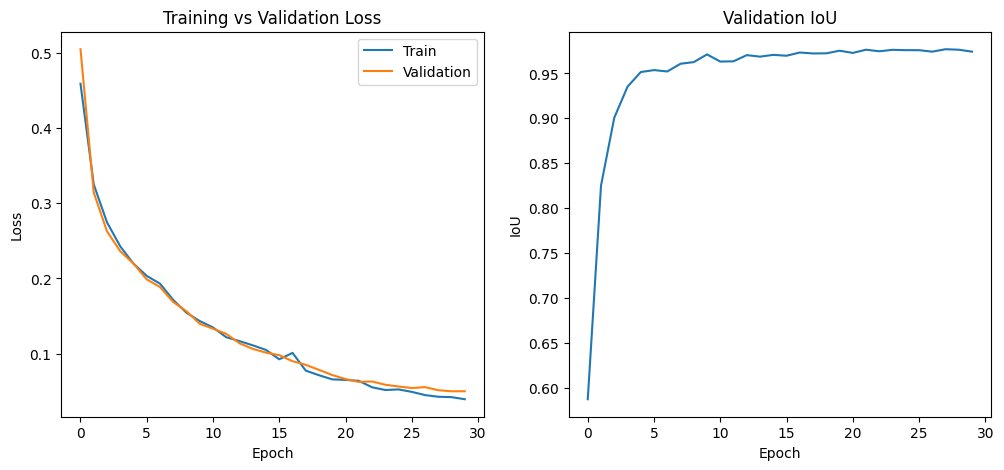

In [ ]:
import json

DRIVE_DIR = "/content/drive/MyDrive/phone_box_training"
HISTORY_PATH = f"{DRIVE_DIR}/training_history.json"

with open(HISTORY_PATH) as f:
    history = json.load(f)

train_losses = history["train_losses"]
val_losses = history["val_losses"]
val_ious = history["val_ious"]

print(f"Loaded {len(train_losses)} epochs of history")
import matplotlib.pyplot as plt

plt.figure(figsize=(12,5))
plt.subplot(1,2,1)
plt.plot(train_losses, label="Train")
plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend(); plt.title("Training vs Validation Loss")

plt.subplot(1,2,2)
plt.plot(val_ious)
plt.xlabel("Epoch"); plt.ylabel("IoU"); plt.title("Validation IoU")

plt.savefig("training_curves.png", dpi=150, bbox_inches='tight')




In [ ]:
import json
test_results = {
    "mean_iou": 0.9867,
    "mean_dice": 0.9933,
    "mean_precision": 0.9901,
    "mean_recall": 0.9965,
    "mean_f1": 0.9933,
    "pixel_accuracy": 0.9962
}
with open("/content/drive/MyDrive/phone_box_training/test_metrics.json", "w") as f:
    json.dump(test_results, f, indent=2)

In [ ]:
import shutil
shutil.copy("training_curves.png", "/content/drive/MyDrive/phone_box_training/training_curves.png")

'/content/drive/MyDrive/phone_box_training/training_curves.png'